In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


In [4]:
master_df = pd.read_csv('data/master_data.csv')

C:\Users\Seyoung\AppData\Local\Temp\ipykernel_20548\4212149373.py:1: DtypeWarning: Columns (0,3,4,6,7,8,9,10,11,12,13,14,15,17,18,19,20,21,22,23,24,25,28,29,30,31,32,34,35,36,38,39,40,41,43,44,45,47,48,49,51,52,53,55,57,58,59,61,62,63) have mixed types. Specify dtype option on import or set low_memory=False.
  master_df = pd.read_csv('data/master_data.csv')


In [5]:

person_df = master_df.groupby('customer_id')

column_labels =['transaction_id','customer_id','abm_amount','abm_debit_credit','abm_datetime', 
                'abm_cash_indicator','abm_country', 'abm_province', 'abm_city',
                ]

master_df.columns

Index(['transaction_id', 'customer_id', 'abm_amount', 'abm_debit_credit',
       'abm_datetime', 'abm_cash_indicator', 'abm_country', 'abm_province',
       'abm_city', 'from_abm', 'customer_country', 'customer_province',
       'customer_city', 'customer_gender', 'customer_marital_status',
       'customer_occupation_code', 'customer_income', 'customer_birth_date',
       'customer_onboard_date', 'from_kyc_individual',
       'customer_occupation_title', 'from_kyc_occupation_codes',
       'business_country', 'business_province', 'business_city',
       'business_industry_code', 'business_employee_count', 'business_sales',
       'business_established_date', 'business_onboard_date',
       'from_kyc_smallbusiness', 'business_industry',
       'from_kyc_industry_codes', 'card_amount', 'card_debit_credit',
       'card_datetime', 'card_merchant_category', 'card_ecommerce_indicator',
       'card_country', 'card_province', 'card_city', 'from_card',
       'cheque_amount', 'cheque_debit_c

In [6]:
abm_df = master_df[['customer_id', 'abm_amount', 'abm_debit_credit', 'abm_datetime']].copy()
abm_df = abm_df.rename(columns={
    'abm_amount': 'amount',
    'abm_debit_credit': 'debit_credit',
    'abm_datetime': 'date'
})
abm_df['transaction_method'] = 'abm'
abm_df = abm_df.dropna(subset=['amount'])
abm_df['date'] = (
    pd.to_datetime(abm_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)


card_df = master_df[['customer_id', 'card_amount', 'card_debit_credit', 'card_datetime']].copy()
card_df = card_df.rename(columns={
    'card_amount': 'amount',
    'card_debit_credit': 'debit_credit',
    'card_datetime': 'date'
})
card_df['transaction_method'] = 'card'
card_df = card_df.dropna(subset=['amount'])
card_df['date'] = (
    pd.to_datetime(card_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)


cheque_df = master_df[['customer_id', 'cheque_amount', 'cheque_debit_credit', 'cheque_datetime']].copy()
cheque_df = cheque_df.rename(columns={
    'cheque_amount': 'amount',
    'cheque_debit_credit': 'debit_credit',
    'cheque_datetime': 'date'
})
cheque_df['transaction_method'] = 'cheque'
cheque_df = cheque_df.dropna(subset=['amount'])
cheque_df['date'] = (
    pd.to_datetime(cheque_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)



eft_df = master_df[['customer_id', 'eft_amount', 'eft_debit_credit', 'eft_datetime']].copy()
eft_df = eft_df.rename(columns={
    'eft_amount': 'amount',
    'eft_debit_credit': 'debit_credit',
    'eft_datetime': 'date'
})
eft_df['transaction_method'] = 'eft'
eft_df = eft_df.dropna(subset=['amount'])
eft_df['date'] = (
    pd.to_datetime(eft_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)



emt_df = master_df[['customer_id', 'emt_amount', 'emt_debit_credit', 'emt_datetime']].copy()
emt_df = emt_df.rename(columns={
    'emt_amount': 'amount',
    'emt_debit_credit': 'debit_credit',
    'emt_datetime': 'date'
})
emt_df['transaction_method'] = 'emt'
emt_df = emt_df.dropna(subset=['amount'])
emt_df['date'] = (
    pd.to_datetime(emt_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)



westernunion_df = master_df[['customer_id', 'westernunion_amount', 'westernunion_debit_credit', 'westernunion_datetime']].copy()
westernunion_df = westernunion_df.rename(columns={
    'westernunion_amount': 'amount',
    'westernunion_debit_credit': 'debit_credit',
    'westernunion_datetime': 'date'
})
westernunion_df['transaction_method'] = 'westernunion'
westernunion_df = westernunion_df.dropna(subset=['amount'])
westernunion_df['date'] = (
    pd.to_datetime(westernunion_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)


wire_df = master_df[['customer_id', 'wire_amount', 'wire_debit_credit', 'wire_datetime']].copy()
wire_df = wire_df.rename(columns={
    'wire_amount': 'amount',
    'wire_debit_credit': 'debit_credit',
    'wire_datetime': 'date'
})
wire_df['transaction_method'] = 'wire'
wire_df = wire_df.dropna(subset=['amount'])
wire_df['date'] = (
    pd.to_datetime(wire_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)


transactions_long = pd.concat([abm_df, card_df, cheque_df, eft_df, emt_df,
                               westernunion_df, wire_df], ignore_index=True)


person_df = transactions_long.groupby('customer_id').agg(
    num_transactions = ('amount', 'count'),
    total_amount = ('amount', 'sum'),
    avg_amount = ('amount', 'mean'),
    max_amount = ('amount', 'max'),
    std_amount = ('amount', 'std'),
    num_debit = ('debit_credit', lambda x: (x=='debit').sum()),
    num_credit = ('debit_credit', lambda x: (x=='credit').sum()),
    num_abm = ('transaction_method', lambda x: (x=='abm').sum()),
    num_card = ('transaction_method', lambda x: (x=='card').sum()),
    num_cheque = ('transaction_method', lambda x: (x=='cheque').sum()),
    num_eft = ('transaction_method', lambda x: (x=='eft').sum()),
    num_emt = ('transaction_method', lambda x: (x=='emt').sum()),
    num_westernunion = ('transaction_method', lambda x: (x=='westernunion').sum()),
    num_wire = ('transaction_method', lambda x: (x=='wire').sum())
)

person_df

,num_transactions,total_amount,avg_amount,max_amount,std_amount,num_debit,num_credit,num_abm,num_card,num_cheque,num_eft,num_emt,num_westernunion,num_wire
customer_id,,,,,,,,,,,,,,
SYNID0100000167,18,11562.53,642.362778,3236.46,816.759765,0,0,0,0,1,17,0,0,0
SYNID0100000431,108,22360.92,207.045556,1753.40,332.131472,0,0,14,45,0,20,28,1,0
SYNID0100000485,40,10991.32,274.783000,2264.88,431.253783,0,0,2,19,0,19,0,0,0
SYNID0100000539,150,10409.15,69.394333,1066.48,148.966923,0,0,0,139,0,4,7,0,0
SYNID0100000932,219,175514.88,801.437808,125397.63,8510.250698,0,0,2,189,2,25,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SYNID0200999416,8,475.34,59.417500,241.70,80.820878,0,0,0,8,0,0,0,0,0
SYNID0200999425,9,16480.55,1831.172222,7294.78,2422.614588,0,0,0,0,0,9,0,0,0
SYNID0200999482,20,611931.39,30596.569500,442933.20,97883.731679,0,0,7,1,12,0,0,0,0


In [21]:
# logistic regression features

activity_features = transactions_long.groupby('customer_id').agg(
    total_transactions=('amount', 'count')
)

money_features = transactions_long.groupby('customer_id').agg(
    total_amount=('amount', 'sum'),
    avg_amount=('amount', 'mean'),
    max_amount=('amount', 'max'),
    std_amount=('amount', 'std')
)

debit_credit_features = transactions_long.groupby('customer_id').agg(
    num_debit=('debit_credit', lambda x: (x=='debit').sum()),
    num_credit=('debit_credit', lambda x: (x=='credit').sum())
)

debit_credit_features

channel_features = transactions_long.groupby(['customer_id', 'transaction_method'])['amount'].count().unstack(fill_value=0)

channel_features

transaction_method,abm,card,cheque,eft,emt,westernunion,wire
customer_id,,,,,,,
SYNID0100000167,0,0,1,17,0,0,0
SYNID0100000431,14,45,0,20,28,1,0
SYNID0100000485,2,19,0,19,0,0,0
SYNID0100000539,0,139,0,4,7,0,0
SYNID0100000932,2,189,2,25,1,0,0
...,...,...,...,...,...,...,...
SYNID0200999416,0,8,0,0,0,0,0
SYNID0200999425,0,0,0,9,0,0,0
SYNID0200999482,7,1,12,0,0,0,0


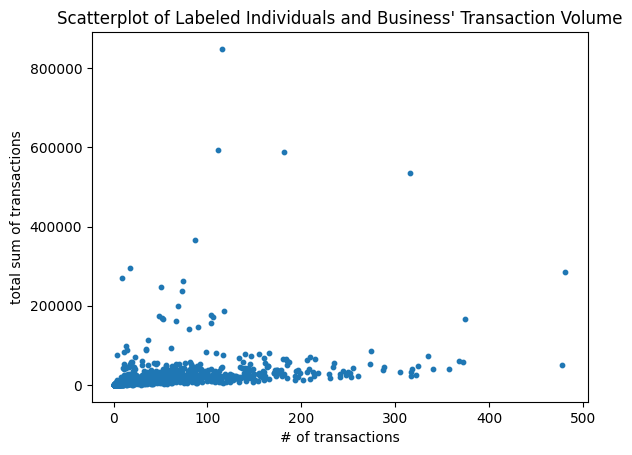

In [18]:
#quick data visualization on the labeled data
import matplotlib.pyplot as plt

labeled_df = pd.read_csv('data/labels.csv')

labeled_df['customer_id']

labeled_people_df = person_df[person_df.index.isin(labeled_df['customer_id'])]

labeled_people_df = labeled_people_df.merge(
    labeled_df[['customer_id','label']],
    on='customer_id',
    how='left'
)

labeled_people_df

plt.scatter(labeled_people_df['num_transactions'], 
            labeled_people_df['total_amount'],
            s=10 
            )
            
plt.ticklabel_format(style = 'plain', axis= 'y')
plt.xlabel('# of transactions')    
plt.ylabel('total sum of transactions') 
plt.title('Scatterplot of Labeled Individuals and Business\' Transaction Volume')
plt.show()

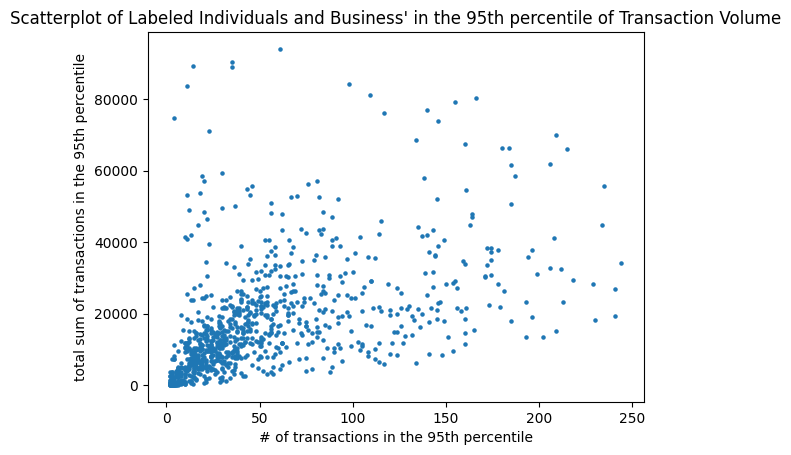

In [19]:
lower_x = labeled_people_df['num_transactions'].quantile(0.025)
upper_x = labeled_people_df['num_transactions'].quantile(0.975)

lower_y = labeled_people_df['total_amount'].quantile(0.025)
upper_y = labeled_people_df['total_amount'].quantile(0.975)

sum_filter = labeled_people_df[
    (labeled_people_df['num_transactions'] >= lower_x) & (labeled_people_df['num_transactions'] <= upper_x) &
    (labeled_people_df['total_amount'] >= lower_y) & (labeled_people_df['total_amount'] <= upper_y)
    ]

plt.scatter(sum_filter['num_transactions'], sum_filter['total_amount'], s = 5)
plt.xlabel('# of transactions in the 95th percentile')    
plt.ylabel('total sum of transactions in the 95th percentile') 
plt.title('Scatterplot of Labeled Individuals and Business\' in the 95th percentile of Transaction Volume')
plt.show()

C:\Users\Seyoung\AppData\Local\Temp\ipykernel_20548\919267959.py:12: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  total_invoice_amt = df.pivot_table(


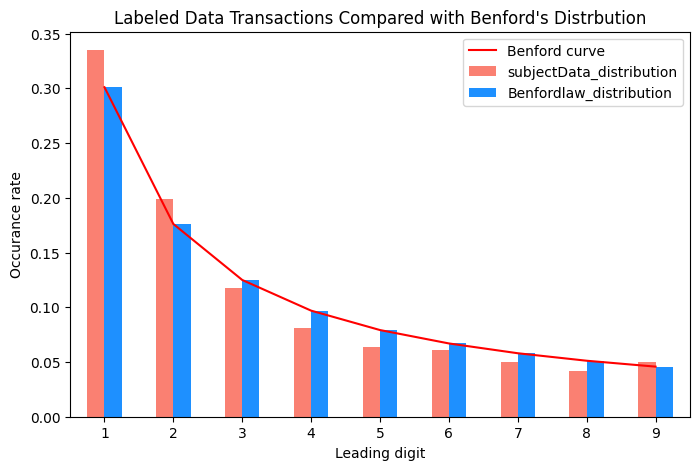

  extract_digit  amount_cad  amount_cad_frequency  subjectData_distribution  \
0             1  6164302.56                   335                     0.335   
1             2  5375879.95                   199                     0.199   
2             3  3114241.83                   118                     0.118   
3             4  1913938.36                    81                     0.081   
4             5  3229667.74                    64                     0.064   
5             6   824406.24                    61                     0.061   
6             7   814066.87                    50                     0.050   
7             8  1703317.17                    42                     0.042   
8             9   641857.45                    50                     0.050   

   Benfordlaw_distribution  
0                 0.301030  
1                 0.176091  
2                 0.124939  
3                 0.096910  
4                 0.079181  
5                 0.066947  
6     

In [20]:
df = pd.DataFrame() 

df['amount_cad'] = labeled_people_df['total_amount'].copy() 
df['extract_digit'] = df['amount_cad'].astype(str).str[:1] 


first_digit_count = df.pivot_table(
    values = ['amount_cad'],
    index = 'extract_digit', aggfunc= len, fill_value=''  
) 

total_invoice_amt = df.pivot_table(
    values = ['amount_cad'],
    index = 'extract_digit', aggfunc=sum, fill_value=''
)

df2 = total_invoice_amt.merge(first_digit_count, how = 'left',
                              left_on = 'extract_digit',
                              right_index= True,
                              suffixes = ['','_frequency'])

df2['subjectData_distribution'] = df2['amount_cad_frequency']/df2['amount_cad_frequency'].sum()

digits = np.arange(1,10)
benford_df = pd.DataFrame({
    'extract_digit': digits,
    'Benfordlaw_distribution': np.log10(1 + 1/digits)
})

benford_df['extract_digit'] = benford_df['extract_digit'].astype(str)


df2 = df2.merge(benford_df, on='extract_digit', how='left')


fig, ax = plt.subplots(figsize = (8, 5))
df2.reset_index()['Benfordlaw_distribution'].plot(kind = "line", ax = ax, secondary_y = False, color =  'red')
ax.legend(["Benford curve"])
df2.plot(kind = 'bar', x = 'extract_digit', y = ['subjectData_distribution','Benfordlaw_distribution'], 
        ax = ax, color = ['salmon','dodgerblue'], rot = 0)

plt.title('Labeled Data Transactions Compared with Benford\'s Distrbution')
plt.xlabel('Leading digit')
plt.ylabel('Occurance rate')
plt.show()


# print(first_digit_count)
# print(total_invoice_amt)
print(df2)


In [12]:
labeled_people_df.loc[labeled_people_df['label'] == 1]

labeled_people_df = labeled_people_df.set_index('customer_id')

In [13]:
labeled_people_df['std_amount'] = labeled_people_df['std_amount'].fillna(0)

X = labeled_people_df.drop(columns = 'label')

Y = labeled_people_df['label']

X_train, X_test, y_train, y_test = train_test_split(X,Y, test_size=0.3, random_state=21)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled)

log_reg = LogisticRegression(random_state = 0).fit(X_train_scaled, y_train)

[[-0.61160864 -0.40592279 -0.17868352 ...  0.67683176 -0.0600223
  -0.12828453]
 [ 0.08051894 -0.0387746  -0.16251212 ...  0.54144607  2.94109261
  -0.12828453]
 [-0.7169324  -0.30038593  0.2505242  ... -0.60933232 -0.0600223
  -0.12828453]
 ...
 [-0.35582236 -0.47158251 -0.35190492 ...  0.20298183 -0.0600223
  -0.12828453]
 [-0.44609987 -0.03265355  0.14277267 ... -0.60933232 -0.0600223
  -0.12828453]
 [ 0.21593521  5.62024368  2.3224029  ... -0.40625378 -0.0600223
  -0.12828453]]


In [26]:
log_reg.predict(X_train_scaled)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [27]:
log_reg.score(X_test_scaled, y_test)

0.9866666666666667

In [28]:
log_reg.score(X_train_scaled,y_train)

0.99

In [23]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

def evaluate_prob_model(name, model, X_te, y_te, threshold=0.5):
    """
    Evaluate a model using ROC-AUC + PR-AUC (PR-AUC is important for imbalanced AML labels).
    Works for models that implement predict_proba (logistic, RF, XGB).
    """
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)

    print(f"\n===== {name} (threshold={threshold}) =====")
    print("ROC-AUC :", roc_auc_score(y_te, proba))
    print("PR-AUC  :", average_precision_score(y_te, proba))
    print("Confusion matrix:\n", confusion_matrix(y_te, pred))
    print(classification_report(y_te, pred, digits=3))
    return proba

# Evaluate logistic regression properly (NOT just accuracy)
log_proba = evaluate_prob_model(
    "Logistic Regression",
    log_reg,
    X_test_scaled,   # scaled for logistic
    y_test,
    threshold=0.5
)


===== Logistic Regression (threshold=0.5) =====
ROC-AUC : 0.3406040268456376
PR-AUC  : 0.008541666666666666
Confusion matrix:
 [[296   2]
 [  2   0]]
              precision    recall  f1-score   support

           0      0.993     0.993     0.993       298
           1      0.000     0.000     0.000         2

    accuracy                          0.987       300
   macro avg      0.497     0.497     0.497       300
weighted avg      0.987     0.987     0.987       300



In [24]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=5,
    class_weight="balanced",
    n_jobs=-1,
    random_state=21
)

rf.fit(X_train, y_train)

rf_proba = evaluate_prob_model(
    "Random Forest",
    rf,
    X_test,          # UNscaled for trees
    y_test,
    threshold=0.5
)


===== Random Forest (threshold=0.5) =====
ROC-AUC : 0.4597315436241611
PR-AUC  : 0.015631548068058
Confusion matrix:
 [[295   3]
 [  2   0]]
              precision    recall  f1-score   support

           0      0.993     0.990     0.992       298
           1      0.000     0.000     0.000         2

    accuracy                          0.983       300
   macro avg      0.497     0.495     0.496       300
weighted avg      0.987     0.983     0.985       300



In [25]:
from xgboost import XGBClassifier

pos = int((y_train == 1).sum())
neg = int((y_train == 0).sum())
scale_pos_weight = neg / max(pos, 1)

xgb = XGBClassifier(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    n_jobs=-1,
    random_state=21
)

xgb.fit(X_train, y_train)

xgb_proba = evaluate_prob_model(
    "XGBoost (Gradient Boosted Trees)",
    xgb,
    X_test,          # UNscaled for trees is fine
    y_test,
    threshold=0.5
)


===== XGBoost (Gradient Boosted Trees) (threshold=0.5) =====
ROC-AUC : 0.8129194630872483
PR-AUC  : 0.025807525807525808
Confusion matrix:
 [[295   3]
 [  2   0]]
              precision    recall  f1-score   support

           0      0.993     0.990     0.992       298
           1      0.000     0.000     0.000         2

    accuracy                          0.983       300
   macro avg      0.497     0.495     0.496       300
weighted avg      0.987     0.983     0.985       300



In [29]:
# Score the full population (all customers) with all three models (Logistic Regression, Random Forest, Gradient Boosted Tree)

X_new = person_df.copy()
X_new['std_amount'] = X_new['std_amount'].fillna(0)

# 1) Logistic Regression (needs scaling)
X_new_scaled = scaler.transform(X_new)

log_probabilities = log_reg.predict_proba(X_new_scaled)[:, 1]
log_threshold = 0.1
log_flags = (log_probabilities >= log_threshold).astype(int)

# 2) Random Forest (NO scaling)
rf_probabilities = rf.predict_proba(X_new)[:, 1]
rf_threshold = 0.1
rf_flags = (rf_probabilities >= rf_threshold).astype(int)

# 3) XGBoost (NO scaling)
xgb_probabilities = xgb.predict_proba(X_new)[:, 1]
xgb_threshold = 0.1
xgb_flags = (xgb_probabilities >= xgb_threshold).astype(int)

# Attach results to the same dataframe
X_new['log_prob'] = log_probabilities
X_new['log_flag'] = log_flags

X_new['rf_prob'] = rf_probabilities
X_new['rf_flag'] = rf_flags

X_new['xgb_prob'] = xgb_probabilities
X_new['xgb_flag'] = xgb_flags

# Quick sanity check: how many customers each model flags
print("Flag counts @ threshold 0.1")
print("Logistic:", X_new['log_flag'].sum())
print("RF      :", X_new['rf_flag'].sum())
print("XGBoost  :", X_new['xgb_flag'].sum())

Flag counts @ threshold 0.1
Logistic: 3192
RF      : 18231
XGBoost  : 4578


In [30]:
top_n = 50  # change as you like

top_log = X_new.sort_values("log_prob", ascending=False).head(top_n)
top_rf  = X_new.sort_values("rf_prob", ascending=False).head(top_n)
top_xgb = X_new.sort_values("xgb_prob", ascending=False).head(top_n)

print("\nTop Logistic customers:")
display(top_log[["log_prob", "log_flag"]].head(10))

print("\nTop RF customers:")
display(top_rf[["rf_prob", "rf_flag"]].head(10))

print("\nTop XGBoost customers:")
display(top_xgb[["xgb_prob", "xgb_flag"]].head(10))


Top Logistic customers:


,log_prob,log_flag
customer_id,,
SYNID0200999280,1.0,1
SYNID0200996396,1.0,1
SYNID0101186911,1.0,1
SYNID0105579175,1.0,1
SYNID0200931678,1.0,1
SYNID0105359473,1.0,1
SYNID0200917657,1.0,1
SYNID0105351153,1.0,1
SYNID0200911238,1.0,1



Top RF customers:


,rf_prob,rf_flag
customer_id,,
SYNID0200755995,0.746550,1
SYNID0200763435,0.744811,1
SYNID0200498815,0.738035,1
SYNID0200061628,0.730328,1
SYNID0200534513,0.729352,1
SYNID0200109884,0.726311,1
SYNID0200353709,0.722915,1
SYNID0200075093,0.722270,1
SYNID0200789296,0.716157,1



Top XGBoost customers:


,xgb_prob,xgb_flag
customer_id,,
SYNID0105593361,0.998531,1
SYNID0200847807,0.998275,1
SYNID0200567030,0.997653,1
SYNID0200755995,0.997566,1
SYNID0105660335,0.997534,1
SYNID0104511912,0.997371,1
SYNID0107334515,0.997012,1
SYNID0200458134,0.997009,1
SYNID0200755574,0.996998,1


In [ ]:
# Consensus flags: Flag only if multiple models agree

# Case 1: 2 out of 3 models agree
X_new["vote_sum"] = X_new["log_flag"] + X_new["rf_flag"] + X_new["xgb_flag"]
X_new["flag_2of3"] = (X_new["vote_sum"] >= 2).astype(int)

print("Consensus (2 of 3) flagged:", X_new["flag_2of3"].sum())

# Case 2: All 3 models agree (reduces false positives)
X_new["flag_3of3"] = (X_new["vote_sum"] == 3).astype(int)
print("Consensus (3 of 3) flagged:", X_new["flag_3of3"].sum())

Consensus (2 of 3) flagged: 5504
Consensus (3 of 3) flagged: 2241


In [40]:
# Model-by-model summary (after consensus flags)

def summarize_flags(df, flag_col, prob_col, top_n=10):
    print(f"\n--- {flag_col} summary ---")
    print("Flagged count:", int(df[flag_col].sum()))
    print("Flag rate:", round(df[flag_col].mean(), 4))

    top = df.sort_values(prob_col, ascending=False).head(top_n)
    display(top[[prob_col, flag_col]].head(top_n))

# Logistic summary
summarize_flags(X_new, "log_flag", "log_prob", top_n=10)

# Random Forest summary
summarize_flags(X_new, "rf_flag", "rf_prob", top_n=10)

# XGBoost summary
summarize_flags(X_new, "xgb_flag", "xgb_prob", top_n=10)

# Consensus summaries
summarize_flags(X_new, "flag_2of3", "xgb_prob", top_n=10)  # using xgb_prob just for sorting preview
summarize_flags(X_new, "flag_3of3", "xgb_prob", top_n=10)


--- log_flag summary ---
Flagged count: 3192
Flag rate: 0.052


,log_prob,log_flag
customer_id,,
SYNID0200999280,1.0,1
SYNID0200996396,1.0,1
SYNID0101186911,1.0,1
SYNID0105579175,1.0,1
SYNID0200931678,1.0,1
SYNID0105359473,1.0,1
SYNID0200917657,1.0,1
SYNID0105351153,1.0,1
SYNID0200911238,1.0,1



--- rf_flag summary ---
Flagged count: 18231
Flag rate: 0.2969


,rf_prob,rf_flag
customer_id,,
SYNID0200755995,0.746550,1
SYNID0200763435,0.744811,1
SYNID0200498815,0.738035,1
SYNID0200061628,0.730328,1
SYNID0200534513,0.729352,1
SYNID0200109884,0.726311,1
SYNID0200353709,0.722915,1
SYNID0200075093,0.722270,1
SYNID0200789296,0.716157,1



--- xgb_flag summary ---
Flagged count: 4578
Flag rate: 0.0745


,xgb_prob,xgb_flag
customer_id,,
SYNID0105593361,0.998531,1
SYNID0200847807,0.998275,1
SYNID0200567030,0.997653,1
SYNID0200755995,0.997566,1
SYNID0105660335,0.997534,1
SYNID0104511912,0.997371,1
SYNID0107334515,0.997012,1
SYNID0200458134,0.997009,1
SYNID0200755574,0.996998,1



--- flag_2of3 summary ---
Flagged count: 5504
Flag rate: 0.0896


,xgb_prob,flag_2of3
customer_id,,
SYNID0105593361,0.998531,1
SYNID0200847807,0.998275,1
SYNID0200567030,0.997653,1
SYNID0200755995,0.997566,1
SYNID0105660335,0.997534,1
SYNID0104511912,0.997371,1
SYNID0107334515,0.997012,1
SYNID0200458134,0.997009,1
SYNID0200755574,0.996998,1



--- flag_3of3 summary ---
Flagged count: 2241
Flag rate: 0.0365


,xgb_prob,flag_3of3
customer_id,,
SYNID0105593361,0.998531,0
SYNID0200847807,0.998275,0
SYNID0200567030,0.997653,1
SYNID0200755995,0.997566,1
SYNID0105660335,0.997534,1
SYNID0104511912,0.997371,1
SYNID0107334515,0.997012,0
SYNID0200458134,0.997009,1
SYNID0200755574,0.996998,0


In [ ]:
# A prioritized list: Combined risk score + ranked case lists

# Average probability across models (simple + effective)
X_new["risk_score_mean"] = (X_new["log_prob"] + X_new["rf_prob"] + X_new["xgb_prob"]) / 3

# Optional: weighted average (if you trust XGB more)
# X_new["risk_score_weighted"] = 0.2*X_new["log_prob"] + 0.3*X_new["rf_prob"] + 0.5*X_new["xgb_prob"]

# Case lists
case_list_2of3 = X_new[X_new["flag_2of3"] == 1].sort_values("risk_score_mean", ascending=False)
case_list_3of3 = X_new[X_new["flag_3of3"] == 1].sort_values("risk_score_mean", ascending=False)

print("Top 20 cases (2-of-3):")
display(case_list_2of3[["risk_score_mean","log_prob","rf_prob","xgb_prob","flag_2of3","flag_3of3"]].head(20))

print("Top 20 cases (3-of-3):")
display(case_list_3of3[["risk_score_mean","log_prob","rf_prob","xgb_prob","flag_2of3","flag_3of3"]].head(20))

Top 20 cases (2-of-3):


,risk_score_mean,log_prob,rf_prob,xgb_prob,flag_2of3,flag_3of3
customer_id,,,,,,
SYNID0200061628,0.906579,0.994719,0.730328,0.994691,1,1
SYNID0200075093,0.905318,0.999998,0.722270,0.993686,1,1
SYNID0200353709,0.904105,0.999999,0.722915,0.989401,1,1
SYNID0200498815,0.903607,0.999998,0.738035,0.972788,1,1
SYNID0200885292,0.899937,0.999452,0.710640,0.989718,1,1
SYNID0200293964,0.899254,0.998781,0.704332,0.994649,1,1
SYNID0200684273,0.896546,0.999299,0.708138,0.982202,1,1
SYNID0200623494,0.896421,0.991267,0.712606,0.985389,1,1
SYNID0200886350,0.895729,0.999899,0.705701,0.981587,1,1


Top 20 cases (3-of-3):


,risk_score_mean,log_prob,rf_prob,xgb_prob,flag_2of3,flag_3of3
customer_id,,,,,,
SYNID0200061628,0.906579,0.994719,0.730328,0.994691,1,1
SYNID0200075093,0.905318,0.999998,0.722270,0.993686,1,1
SYNID0200353709,0.904105,0.999999,0.722915,0.989401,1,1
SYNID0200498815,0.903607,0.999998,0.738035,0.972788,1,1
SYNID0200885292,0.899937,0.999452,0.710640,0.989718,1,1
SYNID0200293964,0.899254,0.998781,0.704332,0.994649,1,1
SYNID0200684273,0.896546,0.999299,0.708138,0.982202,1,1
SYNID0200623494,0.896421,0.991267,0.712606,0.985389,1,1
SYNID0200886350,0.895729,0.999899,0.705701,0.981587,1,1


In [46]:
# Reason codes: A system to answer why did the system flag this customer?

# Use high quantile cutoffs to tag “unusual” behavior
q99 = X_new.quantile(0.99, numeric_only=True)
q95 = X_new.quantile(0.95, numeric_only=True)

# Rebuild case list AFTER adding reason_codes
case_list_2of3 = X_new[X_new["flag_2of3"] == 1].sort_values("risk_score_mean", ascending=False)

display(case_list_2of3[["risk_score_mean", "reason_codes"]].head(10))

def reason_codes(row):
    reasons = []

    # transaction behavior
    if "num_transactions" in row and row["num_transactions"] >= q99.get("num_transactions", np.inf):
        reasons.append("Very high number of transactions")

    if "total_amount" in row and row["total_amount"] >= q99.get("total_amount", np.inf):
        reasons.append("Very high total transaction amount")

    if "std_amount" in row and row["std_amount"] >= q99.get("std_amount", np.inf):
        reasons.append("Highly irregular transaction amounts")

    # channel-specific (edit names to match your columns)
    for col, label in [
        ("wire_amount", "High wire transfer amount"),
        ("westernunion_amount", "High Western Union amount"),
        ("emt_amount", "High EMT amount"),
        ("eft_amount", "High EFT amount"),
        ("card_amount", "High card amount"),
        ("cheque_amount", "High cheque amount"),
        ("abm_amount", "High cash/ABM amount"),
    ]:
        if col in row and row[col] >= q99.get(col, np.inf):
            reasons.append(label)


    if "debit_credit_ratio" in row and row["debit_credit_ratio"] >= q99.get("debit_credit_ratio", np.inf):
        reasons.append("Unusual debit/credit pattern")

    return "; ".join(reasons) if reasons else "No single extreme feature (interaction-based risk)"

X_new["reason_codes"] = X_new.apply(reason_codes, axis=1)

print("Example reasons for top 10 (2-of-3) cases:")
display(case_list_2of3[["risk_score_mean","reason_codes"]].head(10))

,risk_score_mean,reason_codes
customer_id,,
SYNID0200061628,0.906579,No single extreme feature (interaction-based r...
SYNID0200075093,0.905318,No single extreme feature (interaction-based r...
SYNID0200353709,0.904105,Very high total transaction amount; Highly irr...
SYNID0200498815,0.903607,Highly irregular transaction amounts
SYNID0200885292,0.899937,No single extreme feature (interaction-based r...
SYNID0200293964,0.899254,Very high total transaction amount
SYNID0200684273,0.896546,Very high total transaction amount
SYNID0200623494,0.896421,No single extreme feature (interaction-based r...
SYNID0200886350,0.895729,No single extreme feature (interaction-based r...


Example reasons for top 10 (2-of-3) cases:


,risk_score_mean,reason_codes
customer_id,,
SYNID0200061628,0.906579,No single extreme feature (interaction-based r...
SYNID0200075093,0.905318,No single extreme feature (interaction-based r...
SYNID0200353709,0.904105,Very high total transaction amount; Highly irr...
SYNID0200498815,0.903607,Highly irregular transaction amounts
SYNID0200885292,0.899937,No single extreme feature (interaction-based r...
SYNID0200293964,0.899254,Very high total transaction amount
SYNID0200684273,0.896546,Very high total transaction amount
SYNID0200623494,0.896421,No single extreme feature (interaction-based r...
SYNID0200886350,0.895729,No single extreme feature (interaction-based r...


In [47]:
# Optional: Overlap analysis (how the 3 models agree)

log_set = set(X_new.index[X_new["log_flag"] == 1])
rf_set  = set(X_new.index[X_new["rf_flag"] == 1])
xgb_set = set(X_new.index[X_new["xgb_flag"] == 1])

print("Flag overlap counts:")
print("Log ∩ RF:", len(log_set & rf_set))
print("Log ∩ XGB:", len(log_set & xgb_set))
print("RF ∩ XGB:", len(rf_set & xgb_set))
print("All three:", len(log_set & rf_set & xgb_set))

Flag overlap counts:
Log ∩ RF: 3192
Log ∩ XGB: 2241
RF ∩ XGB: 4553
All three: 2241
